# Nhiệm vụ 2: Trò Chơi Đấu Tăng — Thực Nghiệm Tìm Kiếm Đối Kháng

Đánh giá trên cùng kịch bản và điều kiện tìm kiếm cho 4 cấu hình bắt buộc:
1. `Minimax thuần` (Duyệt Minimax tới trạng thái kết thúc)
2. `Alpha-Beta thuần` (Cắt tỉa Alpha-Beta không dùng hàm lượng giá)
3. `Heuristic Minimax` (Cắt tại độ sâu $d$ với hàm lượng giá chiến thuật `EVAL(s)`)
4. `Heuristic Alpha-Beta` (Kết hợp `EVAL(s)`, cắt tỉa Alpha-Beta, sắp xếp nước đi và bảng băm `Transposition Table`)

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 130

current = Path.cwd().resolve()
SOURCE_DIR = current.parent if (current.parent / 'task2').exists() else current / 'source'
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from task2.agents import (
    MinimaxAgent,
    AlphaBetaAgent,
    HeuristicMinimaxAgent,
    HeuristicAlphaBetaAgent,
    discover_external_agents,
)
from task2.engine import TankBattleEngine, get_all_scenarios

ACTION_VI = {
    'MOVE_UP': 'LÊN', 'MOVE_DOWN': 'XUỐNG', 'MOVE_LEFT': 'TRÁI',
    'MOVE_RIGHT': 'PHẢI', 'FIRE': 'BẮN', 'STAY': 'ĐỨNG YÊN',
}
FIG_DIR = SOURCE_DIR.parent / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 2 thành công.')

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 2 thành công.


## 1. Kịch Bản Tầng 1 (Tàn Cuộc Sát Nút 7x7): Đối Sánh Công Bằng Cả 4 Cấu Hình

In [2]:
tier1_rows = []
for scen in get_all_scenarios(tier='tier1'):
    s0 = scen.builder()
    configs = [
        MinimaxAgent(max_ply_cap=6, name='Minimax thuần'),
        AlphaBetaAgent(max_ply_cap=6, name='Alpha-Beta thuần'),
        HeuristicMinimaxAgent(max_depth=4, name='Heuristic Minimax'),
        HeuristicAlphaBetaAgent(max_depth=4, name='Heuristic Alpha-Beta'),
    ]
    for agent in configs:
        act = agent.safe_choose_action(s0)
        m = agent.last_metrics
        tier1_rows.append({
            'Kịch bản': scen.title,
            'Cấu hình thuật toán': agent.name,
            'Nước đi chọn': ACTION_VI.get(act, act),
            'Số trạng thái duyệt': m.explored_states,
            'Độ sâu đạt được': m.depth_reached,
            'Nhánh cắt tỉa': m.pruned_branches,
            'Trúng bảng băm (TT)': m.tt_hits,
            'Thời gian (ms)': round(m.elapsed_ms, 2),
        })

df_tier1 = pd.DataFrame(tier1_rows)
df_tier1

,Kịch bản,Cấu hình thuật toán,Nước đi chọn,Số trạng thái duyệt,Độ sâu đạt được,Nhánh cắt tỉa,Trúng bảng băm (TT),Thời gian (ms)
0,Tàn cuộc Đối đầu (7x7),Minimax thuần,BẮN,30278,6,0,0,1250.08
1,Tàn cuộc Đối đầu (7x7),Alpha-Beta thuần,BẮN,2213,6,539,0,87.98
2,Tàn cuộc Đối đầu (7x7),Heuristic Minimax,BẮN,1004,4,0,0,41.55
3,Tàn cuộc Đối đầu (7x7),Heuristic Alpha-Beta,BẮN,34,4,17,2,2.23
4,Tàn cuộc Đua phá căn cứ (7x7),Minimax thuần,TRÁI,35824,6,0,0,1302.79
5,Tàn cuộc Đua phá căn cứ (7x7),Alpha-Beta thuần,TRÁI,975,6,395,0,50.12
6,Tàn cuộc Đua phá căn cứ (7x7),Heuristic Minimax,TRÁI,1369,4,0,0,76.86
7,Tàn cuộc Đua phá căn cứ (7x7),Heuristic Alpha-Beta,TRÁI,240,4,57,14,13.72
8,Tàn cuộc Phục kích góc (7x7),Minimax thuần,TRÁI,39326,6,0,0,1476.43
9,Tàn cuộc Phục kích góc (7x7),Alpha-Beta thuần,TRÁI,1418,6,402,0,59.55


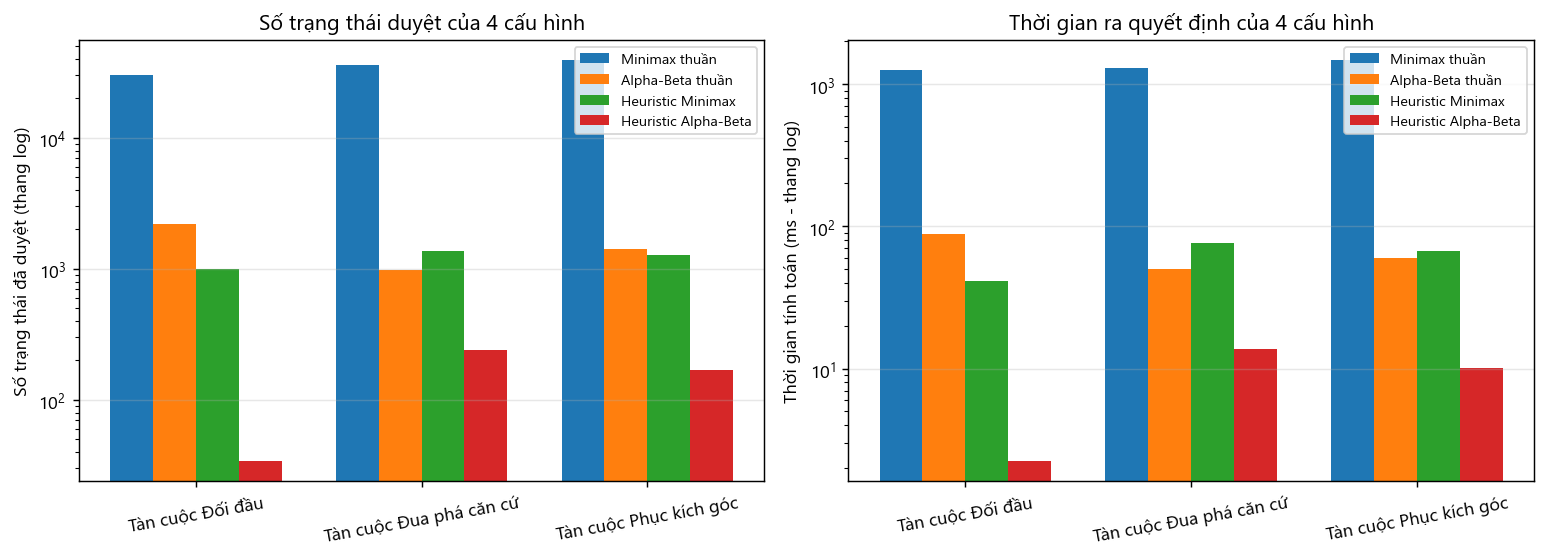

In [3]:
scenarios = df_tier1['Kịch bản'].unique()
configs = ['Minimax thuần', 'Alpha-Beta thuần', 'Heuristic Minimax', 'Heuristic Alpha-Beta']
x = np.arange(len(scenarios))
width = 0.19

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for idx, cfg in enumerate(configs):
    sub = df_tier1[df_tier1['Cấu hình thuật toán'] == cfg]
    axes[0].bar(x + (idx - 1.5) * width, sub['Số trạng thái duyệt'], width, label=cfg)
    axes[1].bar(x + (idx - 1.5) * width, sub['Thời gian (ms)'], width, label=cfg)

axes[0].set_yscale('log')
axes[0].set_xticks(x)
axes[0].set_xticklabels([s.replace(' (7x7)', '') for s in scenarios], rotation=10)
axes[0].set_ylabel('Số trạng thái đã duyệt (thang log)')
axes[0].set_title('Số trạng thái duyệt của 4 cấu hình')
axes[0].legend(fontsize=8)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels([s.replace(' (7x7)', '') for s in scenarios], rotation=10)
axes[1].set_ylabel('Thời gian tính toán (ms - thang log)')
axes[1].set_title('Thời gian ra quyết định của 4 cấu hình')
axes[1].legend(fontsize=8)
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_four_algo_comparison.png', dpi=200)
plt.show()

## 2. Kịch Bản Tầng 2 (Đấu Trường Đầy Máu 9x9 & 11x11): Khảo Sát Độ Sâu & Thi Đấu Với Bot Ngoài

,Bản đồ,Độ sâu d,Thuật toán,Nước đi chọn,Số trạng thái duyệt,Nhánh cắt tỉa,Trúng TT,Thời gian (ms)
0,Đấu trường Cổ điển (9x9),2,Heuristic Minimax,BẮN,31,0,0,1.86
1,Đấu trường Cổ điển (9x9),2,Heuristic Alpha-Beta,BẮN,15,4,0,0.97
2,Đấu trường Cổ điển (9x9),3,Heuristic Minimax,BẮN,166,0,0,7.70
3,Đấu trường Cổ điển (9x9),3,Heuristic Alpha-Beta,BẮN,46,8,0,2.61
4,Đấu trường Cổ điển (9x9),4,Heuristic Minimax,BẮN,895,0,0,48.26
5,Đấu trường Cổ điển (9x9),4,Heuristic Alpha-Beta,BẮN,94,34,5,6.64
6,Công thành Pháo đài (11x11),2,Heuristic Minimax,LÊN,43,0,0,2.55
7,Công thành Pháo đài (11x11),2,Heuristic Alpha-Beta,LÊN,24,4,0,1.73
8,Công thành Pháo đài (11x11),3,Heuristic Minimax,LÊN,253,0,0,15.28
9,Công thành Pháo đài (11x11),3,Heuristic Alpha-Beta,LÊN,85,11,1,6.25


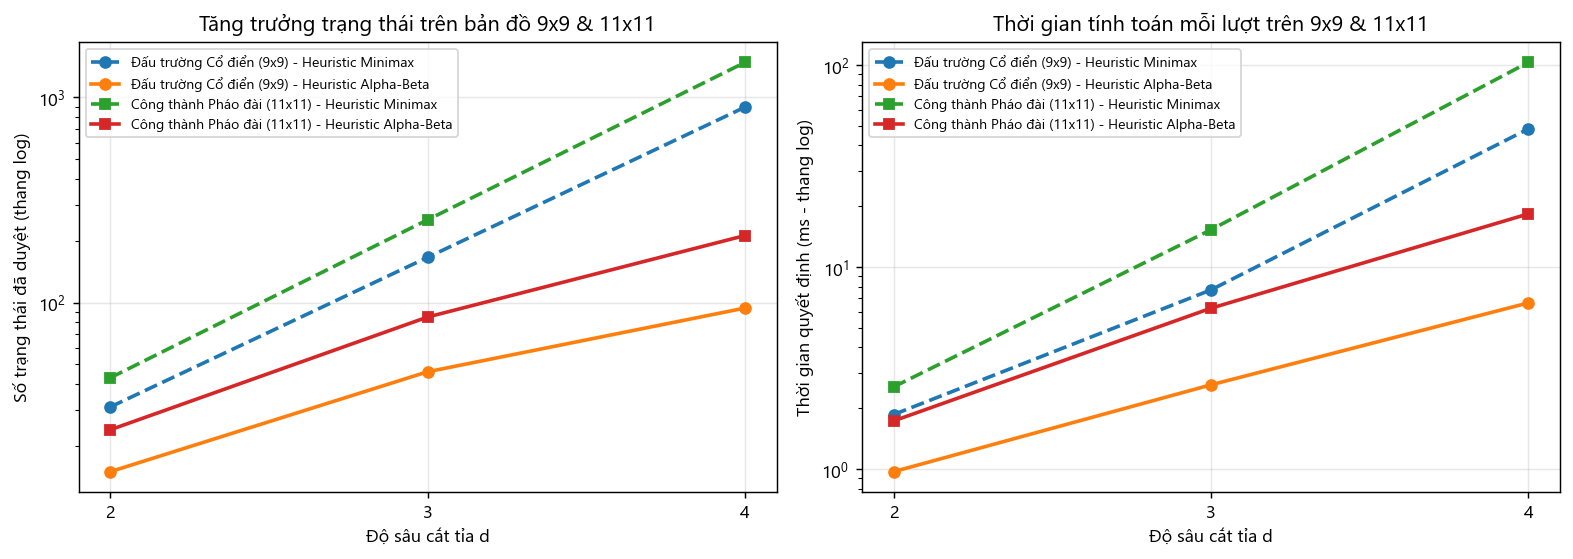

,Phe MAX (Người chơi 1),Phe MIN (Người chơi 2),Tổng số lượt,Máu cuối (MAX Xe/CC vs MIN Xe/CC),Thời gian TB MAX (ms),Kết quả chung cuộc
0,Heuristic Alpha-Beta (sâu 4),Heuristic Minimax (sâu 2),120,6/9 vs 6/9,7.00,Hòa (Hết lượt)
1,Heuristic Alpha-Beta (sâu 4),Bot ngoài: Săn căn cứ (Dict),120,6/9 vs 6/9,6.76,Hòa (Hết lượt)


In [4]:
depth_rows = []
tier2_scenarios = {s.key: s for s in get_all_scenarios(tier='tier2')}
comparison_scenarios = [tier2_scenarios['classic_9x9'], tier2_scenarios['fortress_11x11']]
algorithm_configs = [
    (HeuristicMinimaxAgent, 'Heuristic Minimax'),
    (HeuristicAlphaBetaAgent, 'Heuristic Alpha-Beta'),
]

for scenario in comparison_scenarios:
    arena_state = scenario.builder()
    for d in [2, 3, 4]:
        for cls_ag, label in algorithm_configs:
            agent = cls_ag(max_depth=d, name=f'{label} (d={d})')
            act = agent.safe_choose_action(arena_state)
            m = agent.last_metrics
            depth_rows.append({
                'Bản đồ': scenario.title,
                'Độ sâu d': d,
                'Thuật toán': label,
                'Nước đi chọn': ACTION_VI.get(act, act),
                'Số trạng thái duyệt': m.explored_states,
                'Nhánh cắt tỉa': m.pruned_branches,
                'Trúng TT': m.tt_hits,
                'Thời gian (ms)': round(m.elapsed_ms, 2),
            })

df_depth = pd.DataFrame(depth_rows)
display(df_depth)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
for scen in comparison_scenarios:
    for _, label in algorithm_configs:
        sub = df_depth[(df_depth['Bản đồ'] == scen.title) & (df_depth['Thuật toán'] == label)]
        style = '-' if label == 'Heuristic Alpha-Beta' else '--'
        marker = 'o' if '9x9' in scen.title else 's'
        axes[0].plot(sub['Độ sâu d'], sub['Số trạng thái duyệt'], linestyle=style, marker=marker, linewidth=2, label=f"{scen.title} - {label}")
        axes[1].plot(sub['Độ sâu d'], sub['Thời gian (ms)'], linestyle=style, marker=marker, linewidth=2, label=f"{scen.title} - {label}")

axes[0].set_yscale('log')
axes[0].set_xticks([2, 3, 4])
axes[0].set(xlabel='Độ sâu cắt tỉa d', ylabel='Số trạng thái đã duyệt (thang log)', title='Tăng trưởng trạng thái trên bản đồ 9x9 & 11x11')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=7.8)

axes[1].set_yscale('log')
axes[1].set_xticks([2, 3, 4])
axes[1].set(xlabel='Độ sâu cắt tỉa d', ylabel='Thời gian quyết định (ms - thang log)', title='Thời gian tính toán mỗi lượt trên 9x9 & 11x11')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=7.8)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_tier2_9x9_vs_11x11.png', dpi=200)
plt.show()

ext_bots = discover_external_agents()
match_rows = []
matchups = [
    ('Heuristic Alpha-Beta (sâu 4)', HeuristicAlphaBetaAgent(max_depth=4), 'Heuristic Minimax (sâu 2)', HeuristicMinimaxAgent(max_depth=2)),
    ('Heuristic Alpha-Beta (sâu 4)', HeuristicAlphaBetaAgent(max_depth=4), ext_bots[0].name, ext_bots[0]),
]
for p1_name, p1, p2_name, p2 in matchups:
    st = tier2_scenarios['crossfire_9x9'].builder()
    p1_times = []
    while not st.is_terminal():
        active = p1 if st.current_player == 1 else p2
        act = active.safe_choose_action(st)
        if st.current_player == 1:
            p1_times.append(active.last_metrics.elapsed_ms)
        st = TankBattleEngine.apply_action(st, act)
    w = st.winner()
    ket_qua = p1_name if w == 1 else (p2_name if w == 2 else 'Hòa (Hết lượt)')
    match_rows.append({
        'Phe MAX (Người chơi 1)': p1_name,
        'Phe MIN (Người chơi 2)': p2_name,
        'Tổng số lượt': st.ply,
        'Máu cuối (MAX Xe/CC vs MIN Xe/CC)': f"{st.tanks[1].hp}/{st.bases[1].hp} vs {st.tanks[2].hp}/{st.bases[2].hp}",
        'Thời gian TB MAX (ms)': round(sum(p1_times) / max(1, len(p1_times)), 2),
        'Kết quả chung cuộc': ket_qua,
    })
pd.DataFrame(match_rows)